In [2]:
print("Hello shubham")

Hello shubham


In [3]:
pip install pandas numpy matplotlib seaborn scipy

  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl (37.4 MB)



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
df = pd.read_csv("Task3_Student_Performance.csv")

In [6]:
print(df)

   Student_ID  Study_Hours  Attendance  Assignment_Score  Internal_Marks  \
0      STU001          5.3        83.2              65.3            83.6   
1      STU002          3.0        87.4              61.9            50.0   
2      STU003          6.1        86.5              67.4            82.1   
3      STU004          6.4        96.5              73.4            77.1   
4      STU005          1.5        63.5              26.4            48.5   
..        ...          ...         ...               ...             ...   
95     STU096          2.3        67.0              48.4            54.5   
96     STU097          2.6        80.5              50.9            62.8   
97     STU098          3.1        74.2              48.1            60.5   
98     STU099          5.5        87.0              49.5            76.9   
99     STU100          3.3        76.9              54.8            55.4   

    Final_Exam_Marks  
0               86.5  
1               70.4  
2               98

In [7]:
df.head()

,Student_ID,Study_Hours,Attendance,Assignment_Score,Internal_Marks,Final_Exam_Marks
0,STU001,5.3,83.2,65.3,83.6,86.5
1,STU002,3.0,87.4,61.9,50.0,70.4
2,STU003,6.1,86.5,67.4,82.1,98.7
3,STU004,6.4,96.5,73.4,77.1,93.7
4,STU005,1.5,63.5,26.4,48.5,54.8


In [9]:
df.shape

(100, 6)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Student_ID        100 non-null    str    
 1   Study_Hours       100 non-null    float64
 2   Attendance        100 non-null    float64
 3   Assignment_Score  100 non-null    float64
 4   Internal_Marks    100 non-null    float64
 5   Final_Exam_Marks  100 non-null    float64
dtypes: float64(5), str(1)
memory usage: 4.8 KB


In [ ]:
cove = df["Study_Hours"].cov(df["Final_Exam_Marks"])

print("Covariance : ",cove)

# Positive covariance: બંને variables સામાન્ય રીતે એક જ directionમાં બદલાય છે.
# Negative covariance: બંને variables સામાન્ય રીતે વિરુદ્ધ directionમાં બદલાય છે.
# Zeroની નજીક: Linear co-movement ઓછું હોઈ શકે છે.

Covariance :  13.470875757575755


In [ ]:
corre = df["Study_Hours"].corr(
    df["Final_Exam_Marks"],
    method="pearson"
)

print("Correlation : ",corre)

#storing positive linear relationship

Correlation :  0.8221668032246161


In [14]:
# matrix 
numeric_df = df.drop(columns=["Student_ID"])

correlation_matrix = numeric_df.corr(method="pearson")

print(correlation_matrix)

                  Study_Hours  Attendance  Assignment_Score  Internal_Marks  \
Study_Hours          1.000000    0.621829          0.638031        0.760169   
Attendance           0.621829    1.000000          0.410380        0.494310   
Assignment_Score     0.638031    0.410380          1.000000        0.468575   
Internal_Marks       0.760169    0.494310          0.468575        1.000000   
Final_Exam_Marks     0.822167    0.565564          0.647719        0.635346   

                  Final_Exam_Marks  
Study_Hours               0.822167  
Attendance                0.565564  
Assignment_Score          0.647719  
Internal_Marks            0.635346  
Final_Exam_Marks          1.000000  


In [15]:
corr_pairs = correlation_matrix.unstack()

# Same variableની correlation એટલે 1.0, તેને remove કરો
corr_pairs = corr_pairs[
    corr_pairs.index.get_level_values(0) !=
    corr_pairs.index.get_level_values(1)
]

# Duplicate pairs remove કરો
corr_pairs = corr_pairs[
    corr_pairs.index.map(lambda x: x[0] < x[1])
]

print("Strongest Positive Correlation:")
print(corr_pairs.sort_values(ascending=False).head())

print("\nNegative Correlations:")
print(corr_pairs[corr_pairs < 0].sort_values())

Strongest Positive Correlation:
Final_Exam_Marks  Study_Hours         0.822167
Internal_Marks    Study_Hours         0.760169
Assignment_Score  Final_Exam_Marks    0.647719
                  Study_Hours         0.638031
Final_Exam_Marks  Internal_Marks      0.635346
dtype: float64

Negative Correlations:
Series([], dtype: float64)


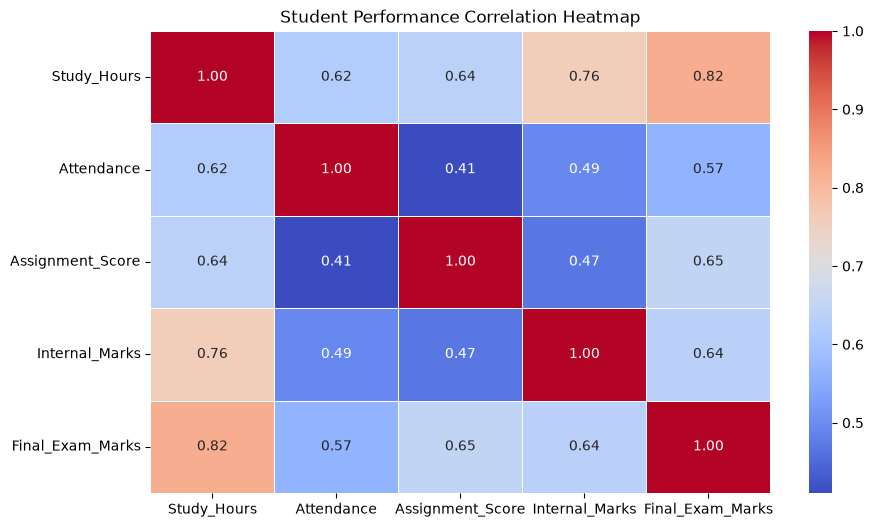

In [16]:
#Heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Student Performance Correlation Heatmap")
plt.show()

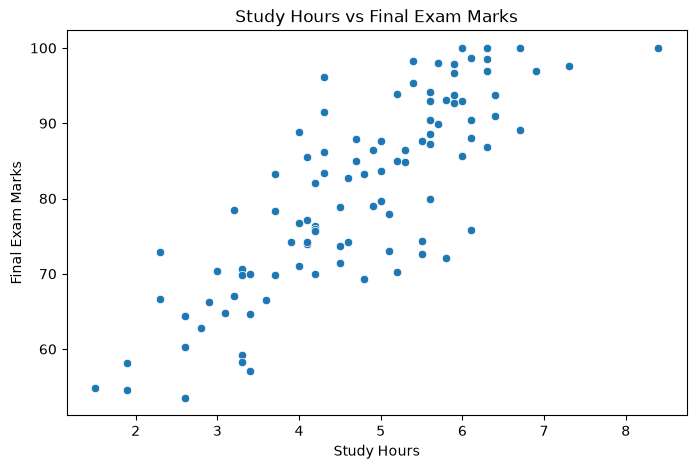

In [17]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Study_Hours",
    y="Final_Exam_Marks"
)

plt.title("Study Hours vs Final Exam Marks")
plt.xlabel("Study Hours")
plt.ylabel("Final Exam Marks")

plt.show()